# Sri Lankan Vehicle Listing Price Prediction

End-to-end activity and final-assignment foundation. Training and saved metric values are in LKR lakhs; app predictions are converted to LKR.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.data import load_data, split_data, FEATURES
df, audit = load_data()
display(pd.Series(audit))
display(df.head())

raw_rows                                                                       9788
clean_rows                                                                     9770
invalid_rows                                                                      0
duplicates_removed                                                               18
missing_raw                       {'Unnamed: 0': 0, 'Brand': 0, 'Model': 0, 'YOM...
mileage_formula_match_fraction                                                  1.0
date_min                                                                 2024-12-03
date_max                                                                 2025-02-05
price_unit                                               LKR lakhs (user-confirmed)
dtype: object

,Unnamed: 0,brand,model,year,engine_cc,gear,fuel,Millage(KM),town,date,leasing,condition,air_condition,power_steering,power_mirror,power_window,price,row_id,group
0,1253,HYUNDAI,GRAND I10,2016,1000.0,AUTOMATIC,PETROL,99000.0,BATTARAMULLA,2024-12-03,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,58.0,1253,14076929561589658937
1,71,AUSTIN,MINI COOPER,1969,1300.0,AUTOMATIC,PETROL,616000.0,MATARA,2024-12-04,NO LEASING,USED,AVAILABLE,NOT_AVAILABLE,NOT_AVAILABLE,NOT_AVAILABLE,28.5,71,17048167182074652515
2,136,BMW,730IL,2011,3000.0,AUTOMATIC,PETROL,154000.0,COLOMBO,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,275.0,136,5941692083290413260
3,199,CHERY,QQ,2009,800.0,MANUAL,PETROL,176000.0,HANWELLA,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,15.0,199,5036400770552479301
4,208,CHEVROLET,BEAT,2011,1200.0,MANUAL,PETROL,154000.0,KIRIBATHGODA,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,NOT_AVAILABLE,AVAILABLE,27.5,208,12251886823049489646


## Source audit
The publisher preprocessed the data. All mileage values follow an exact year-based formula and are excluded. The project owner confirmed the source prices are in LKR lakhs. No source nulls does not prove complete original observations.

In [2]:
train, test, demo, cutoff, purged = split_data(df)
print('Training:', len(train), 'Test:', len(test), 'Demo:', len(demo), 'Test starts:', cutoff)
display(train[FEATURES + ['price']].describe(include='all'))
display(train.groupby('brand').agg(count=('price','size'), median_price=('price','median')).sort_values('count', ascending=False).head(15))

Training: 5285 Test: 4073 Demo: 1 Test starts: 2025-01-24


,year,engine_cc,brand,model,gear,fuel,town,leasing,condition,air_condition,power_steering,power_mirror,power_window,price
count,5285.000000,5285.000000,5285,5285,5285,5285,5285,5285,5285,5285,5285,5285,5285,5285.000000
unique,NaN,NaN,48,1061,2,4,106,2,2,2,2,2,2,NaN
top,NaN,NaN,TOYOTA,ALTO,AUTOMATIC,PETROL,COLOMBO,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,NaN
freq,NaN,NaN,1664,202,3327,4269,503,4998,5231,5159,4805,3906,4304,NaN
mean,2006.503122,1269.753264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.794914
std,10.083163,410.665589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.628412
min,1956.000000,573.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.250000
25%,2000.000000,1000.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.593749
50%,2009.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.500000
75%,2015.000000,1500.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.500000


,count,median_price
brand,,
TOYOTA,1664,66.925000
SUZUKI,1319,42.000000
NISSAN,696,28.950000
HONDA,345,75.000000
MITSUBISHI,164,13.000000
MICRO,132,26.800000
PERODUA,130,40.826271
HYUNDAI,102,24.375000
MAZDA,102,29.475000


## Train and compare
The pipeline fits preprocessing within three purged temporal validation folds. Only explicitly configured Random Forest and XGBoost models are evaluated. Select by validation MAE, not test results. Set RETRAIN=True to repeat training; otherwise use saved results.

In [3]:
RETRAIN = False
if RETRAIN or not (ROOT / 'models/model.pkl').exists():
    from src.train import main
    main()
comparison = pd.read_csv(ROOT / 'reports/model_comparison.csv')
display(comparison)
display(pd.read_csv(ROOT / 'reports/experiments.csv'))

,model,cv_mae,cv_std,training_seconds,parameters,test_mae,test_rmse,test_r2,prediction_ms_per_row,train_mae
0,Random Forest,7.148274,0.146047,7.700997,"{""model__max_depth"": 22, ""model__min_samples_l...",5.830394,14.440418,0.893138,0.011817,2.675995
1,XGBoost,7.562429,0.311620,1.401029,"{""model__max_depth"": 7, ""model__n_estimators"":...",6.821414,14.240944,0.896070,0.003980,5.566662


,model,parameters,cv_mae,cv_std
0,Random Forest,"{""model__max_depth"": 12, ""model__min_samples_l...",7.846810,0.421152
1,Random Forest,"{""model__max_depth"": 22, ""model__min_samples_l...",7.148274,0.146047
2,Random Forest,"{""model__max_depth"": 18, ""model__min_samples_l...",7.672327,0.211412
3,XGBoost,"{""model__max_depth"": 3, ""model__n_estimators"":...",8.832997,0.453671
4,XGBoost,"{""model__max_depth"": 5, ""model__n_estimators"":...",7.778316,0.361734
5,XGBoost,"{""model__max_depth"": 7, ""model__n_estimators"":...",7.562429,0.311620


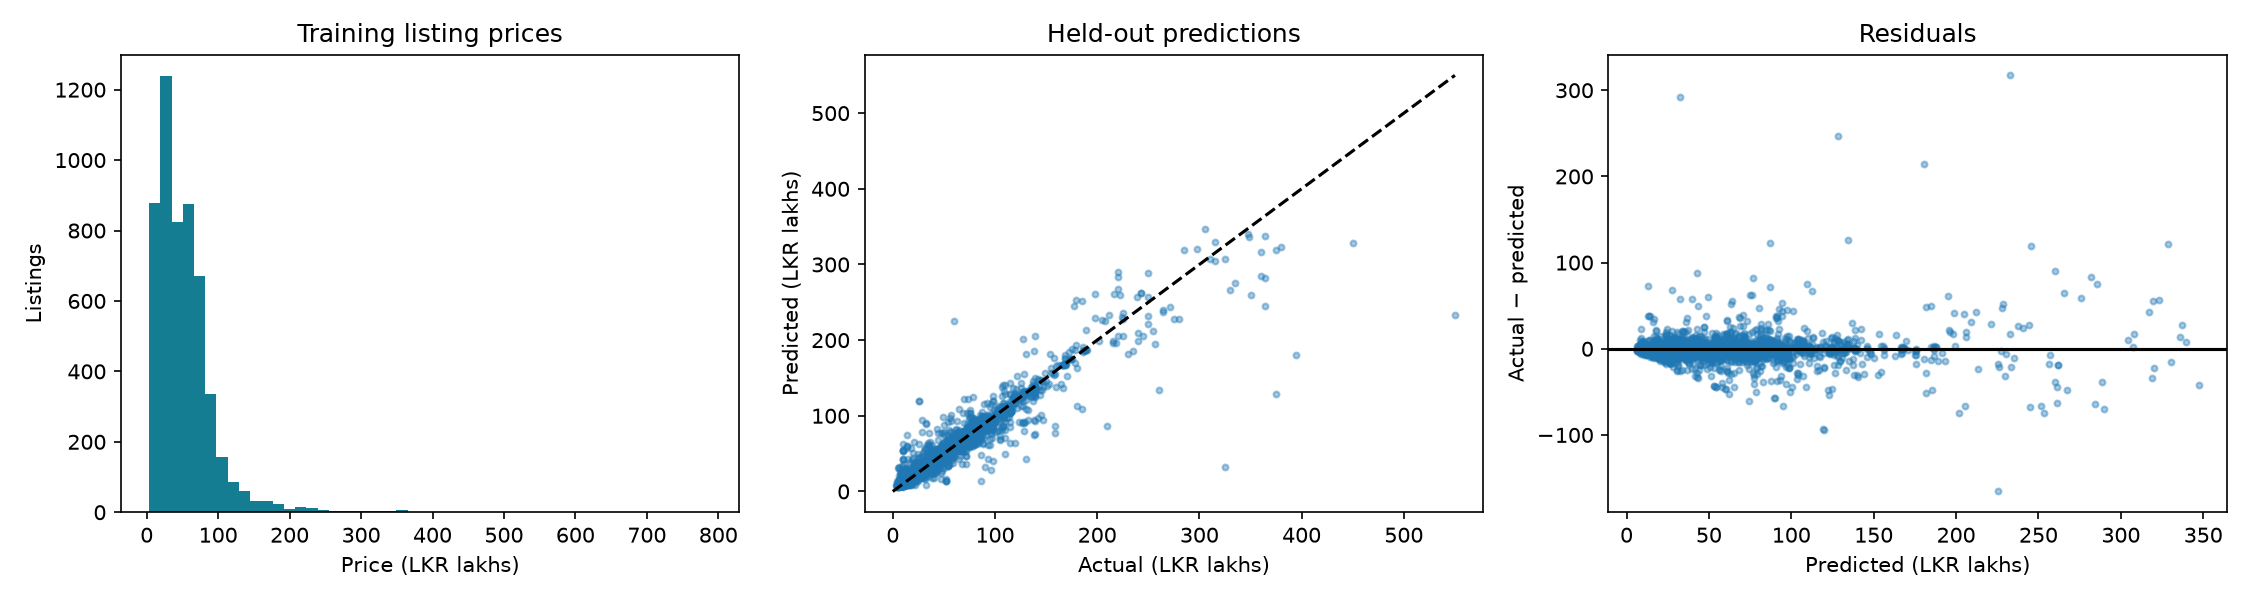

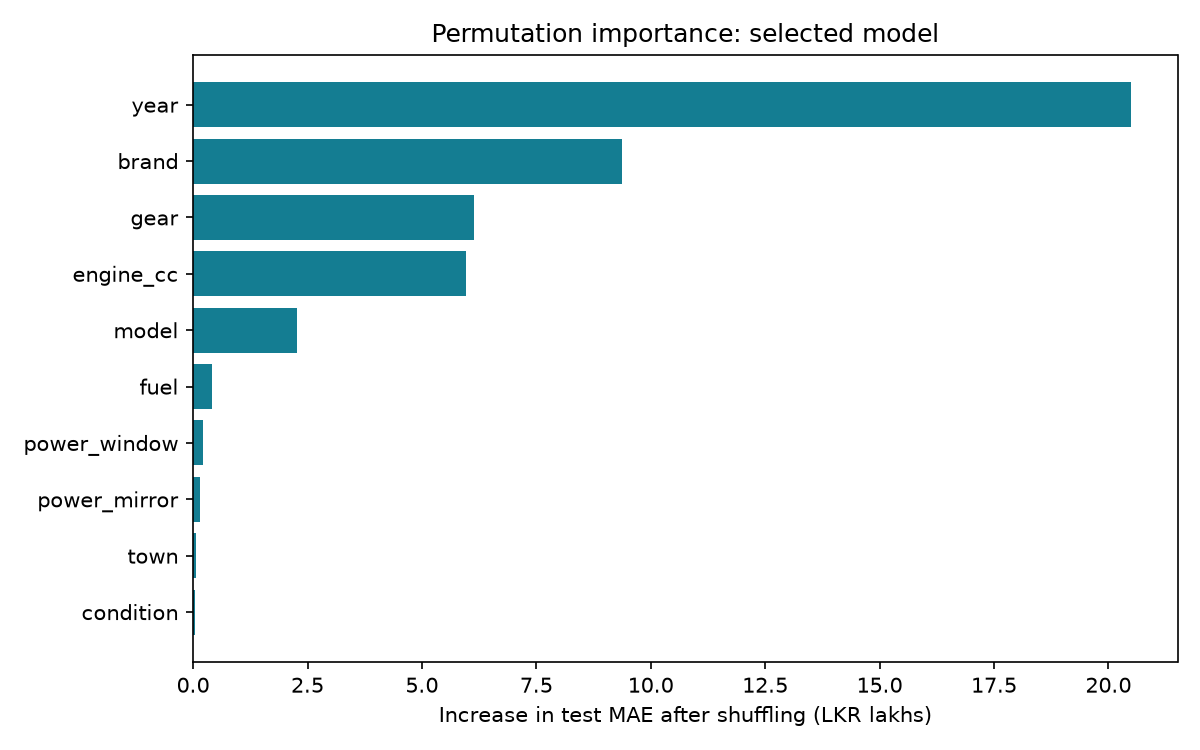

,brand,count,mae
0,TESLA,1,246.767747
1,BYD,1,214.197285
2,MG,2,60.981003
3,FOTON,3,40.227242
4,BMW,39,38.034519
5,MERCEDES-BENZ,80,32.914727
6,SUBARU,5,27.144479
7,JAGUAR,4,24.867617
8,LEXUS,2,24.192649
9,AUDI,17,19.342043


In [4]:
display(Image(filename=str(ROOT / 'reports/figures/evaluation.png')))
display(Image(filename=str(ROOT / 'reports/figures/importance.png')))
display(pd.read_csv(ROOT / 'reports/errors_by_brand.csv').head(15))

## Reload and predict a single unseen record
The demo record and all its feature-signature matches were excluded from development.

In [5]:
from src.predict import predict
example = json.loads((ROOT / 'models/demo.json').read_text())
display(example['input'])
display(predict(example['input']))
print('Actual price (LKR lakhs):', example['actual'])

{'year': 2020,
 'engine_cc': 1000.0,
 'brand': 'ZOTYE',
 'model': 'Z100',
 'gear': 'MANUAL',
 'fuel': 'PETROL',
 'town': 'PANADURA',
 'leasing': 'NO LEASING',
 'condition': 'USED',
 'air_condition': 'AVAILABLE',
 'power_steering': 'AVAILABLE',
 'power_mirror': 'AVAILABLE',
 'power_window': 'AVAILABLE'}

{'prediction': 29.962546221129287,
 'unit': 'LKR lakhs',
 'prediction_lkr': 2996254.622112929,
 'currency': 'LKR',
 'warnings': [],
 'model': 'Random Forest'}

Actual price (LKR lakhs): 30.95


## Interpretation and limitations

In [6]:
display(Markdown((ROOT / 'reports/final_report.md').read_text()))

# Sri Lankan Vehicle Listing Price Prediction

## Objective
Estimate advertised vehicle prices from tabular listing characteristics and compare
Random Forest with XGBoost for the class activity. Intended users are students
and reviewers exploring historical asking-price relationships. This is a coursework
prototype, not a present-day vehicle valuation service.

## Source and provenance
Prasad Nirmal, *SriLankan Vehicle(Car) Price Dataset*, Kaggle version 3:
https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset

Publisher metadata lists MIT licensing and describes listings scraped from Ikman.lk
and Riyasewana.com. The downloaded source has 9,788 rows and 17 columns,
including an exported index. Listings span 2024-12-03 to 2025-02-05.
Metadata and the original CSV are preserved. SHA-256: `4208d2673cf4d9c8d3d6042dc8a1b97004671812441975f5879550059fbce1ab`.

## Data analysis and limitations
- 18 exact duplicates were removed after trimming categories and ignoring the exported index.
- 0 records failed target/date/year validity checks.
- The downloaded table contains no literal nulls, but the publisher already preprocessed it.
- Every mileage value equals `(2025 - YOM) * 11000`. It is excluded as a deterministic proxy for year, not interpreted as measured mileage.
- The project owner confirmed that Price is in LKR lakhs. One lakh equals LKR 100,000. Training metrics remain in lakhs; the app converts monetary values to LKR.
- Model categories are numerous and often rare. Rare-category handling is learned separately within each fold.
- Listing prices are not verified transaction prices. The original listing IDs and full cleaning history are unavailable.

## Evaluation design
The latest record is reserved for a single-sample demonstration; all records with
its feature signature are excluded from development. The final test period starts
2025-01-24. Matching feature signatures are purged from earlier training data,
removing 411 potential overlaps. This conservative proxy can also
exclude distinct cars with identical features; it cannot establish actual identities.

There are 5,285 training records, 4,073 test records and one
demonstration record. Three expanding temporal folds are used inside training.
Validation groups are also excluded from each fold's training partition. The chosen
model minimizes mean validation MAE; test results are computed afterward and are
not used to select or retune it. Fold standard deviations describe variation over
three time windows, not confidence intervals.

## Preprocessing and parameter engineering
Numerical median imputation and categorical most-frequent imputation are fitted
within the pipeline. One-hot encoding pools categories with fewer than three
training observations and handles unknown categories. Both selected
tree models do not require normalization or scaling. Explicit model configurations
and every search result are saved in `experiments.csv` and `src/train.py`.

Random Forest varies tree depth and minimum leaf size while using 180 trees and
80% feature sampling. XGBoost varies depth and number of boosting rounds, with a
0.05 learning rate, 85% row/column sampling and explicit L1/L2 regularization.
Only the two models required for the activity are trained and compared.

## Results
All MAE/RMSE values below are in LKR lakhs (multiply by 100,000 for LKR).

| model | cv_mae | cv_std | test_mae | test_rmse | test_r2 |
|---|---|---|---|---|---|
| Random Forest | 7.148 | 0.146 | 5.830 | 14.440 | 0.893 |
| XGBoost | 7.562 | 0.312 | 6.821 | 14.241 | 0.896 |

The validation-selected model is **Random Forest**. Its held-out MAE is
**5.830**, RMSE **14.440**, and
R² **0.893**. R² is not percentage accuracy. A difference in model scores
is descriptive; this experiment does not prove statistical superiority.

![Evaluation plots](figures/evaluation.png)

XGBoost has a lower test RMSE but a higher test MAE than
Random Forest: it performs better under the metric that penalizes large errors more
strongly, while Random Forest has smaller average absolute errors. The chosen metric
was MAE before evaluation.

## Model strengths and limitations
- **Random Forest:** models nonlinear interactions and offers flexible regularization; can struggle with rare vehicles and cannot reliably extrapolate beyond training prices.
- **XGBoost:** sequentially corrects errors and supports explicit regularization; sensitive to tuning, outliers and distribution changes.

Consult `errors_by_brand.csv` for subgroup counts and MAE. Do not draw strong
conclusions from brands with only a few test observations. `test_predictions.csv`
records individual errors. The residual plot helps identify whether expensive cars
or other regions of the target range have systematically larger errors.

## Interpretation
Manufacture year has the largest permutation importance, followed by brand,
transmission and engine capacity. This suggests that vehicle age and basic market
segment characteristics drive much of the fitted model’s discrimination. It does
not show that changing a feature would cause a corresponding price change.

Permutation importance measures the test MAE increase when a feature is shuffled.
It is descriptive analysis after evaluation; it was not used for further tuning.
Correlated features may share importance, and shuffling can create implausible
combinations. These are global associations, not causal effects or explanations
of a particular car's price.

![Feature importance](figures/importance.png)

## Comparison with an existing approach
Basnayaka (2023), *Prediction of Market Price for Used Cars in Sri Lanka Based on
Machine Learning Approaches*, IIT repository:
https://dlib.iit.ac.lk/xmlui/handle/123456789/1634

The abstract describes comparing linear regression, Random Forest, Extra Trees,
gradient boosting, LightGBM and XGBoost, plus averaging predictions. This project
compares a related subset and adds an explicit documented audit of deterministic
mileage and lakh-based price scaling, temporal evaluation, and feature-signature
purging. The repository abstract's reported “accuracy” is not a directly comparable
MAE/R² benchmark, and an identical dataset/split has not been verified. This is a
methodological comparison, not a claim to outperform that study. A broader literature
review is still appropriate before the final assignment submission.

## Single-sample inference
Reserved source row: 9763. Actual price (LKR lakhs): 30.950; prediction:
29.963; absolute error: 0.987.
The exported pipeline was reloaded and its prediction matched the in-memory model.
Run `python -m src.predict` to repeat this independently.

## Front end and reproducibility
The Streamlit interface accepts the actual model fields, validates inputs, displays
historical estimates in LKR, supports the held-out example and shows model
comparisons. Interface requirements are documented in `docs/interface.md`.
The fitted preprocessing and estimator are exported together in `models/model.pkl`.
Exact installed versions are saved in `requirements-lock.txt`.

## Remaining submission work
The lakh scale is based on the project owner’s confirmation.
Review the analysis and write the student's own interpretation; extend the literature
review if required. Confirm Moodle deadlines. Publish the repository and submit its
link or notebook individually. This project has not been published or submitted.


## Interactive model selection
The app saves and loads both trained pipelines separately. Select a model in
the Prediction model dropdown, then submit the same vehicle details to compare
estimates. Random Forest remains the recommended default based on validation MAE.
Switching clears the previous result and displays the selected model's test MAE.
Downloaded predictions include the model name. The importance chart switches to the selected model's global permutation importance.


## Interpreting the model comparison

Random Forest is recommended because **validation MAE**, chosen before testing, was lower (7.15 versus 7.56 lakhs). Its test MAE is also lower (5.83 versus 6.82 lakhs). XGBoost has a slightly lower test RMSE (14.24 versus 14.44 lakhs) and slightly higher R² (0.896 versus 0.893). These metrics emphasize different aspects of error; neither model wins on every measure. The small R² difference does not demonstrate statistical superiority.

Both models were evaluated on the same 4,073 held-out listings. These results describe historical asking prices, not completed sales or current market valuations. The dataset covers only December 2024–February 2025 and was preprocessed by its publisher. Mileage is excluded because it is entirely calculated from manufacture year. Rare vehicle categories and market changes remain limitations for both models.

### Random Forest: strengths and limitations

**Strengths.** Combines many trees to capture nonlinear relationships between vehicle details. Averaging reduces dependence on one tree. In this experiment it achieved the lowest validation MAE and test MAE, making it the default for average price error.

**Limitations.** The training MAE is substantially smaller than the test MAE, suggesting some overfitting or a difference between the training and later test listings. Averaging tree outputs also limits extrapolation to prices outside the training range. Sparse examples of rare or expensive cars may be unreliable.

**Measured results.** Validation MAE: **7.15 lakhs**; test MAE: **5.83 lakhs**; test RMSE: **14.44 lakhs**; test R²: **0.893**. Training MAE was **2.68 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, gear, engine cc**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **0.08 lakhs**; the largest absolute test error is **317.34 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. Several high-priced listings fall well below the diagonal, indicating substantial underestimation. The residual plot has isolated large positive and negative errors, so neither model is uniformly reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (14.44) is much larger than MAE (5.83), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.

![Random Forest diagnostic graphs](figures/diagnostics_random_forest.png)

### XGBoost: strengths and limitations

**Strengths.** Builds trees sequentially to correct earlier errors and provides explicit regularization. In this experiment it achieved slightly lower test RMSE and slightly higher R², so it performed better under squared-error measures.

**Limitations.** It needs careful choices of depth, learning rate, number of trees and regularization. Its validation and test MAE were higher than Random Forest’s here, despite its better RMSE. Neither its smaller training–test gap nor its slightly higher R² proves it will generalize better to new markets.

**Measured results.** Validation MAE: **7.56 lakhs**; test MAE: **6.82 lakhs**; test RMSE: **14.24 lakhs**; test R²: **0.896**. Training MAE was **5.57 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, engine cc, gear**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **-0.24 lakhs**; the largest absolute test error is **294.56 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. Several high-priced listings fall well below the diagonal, indicating substantial underestimation. The residual plot has isolated large positive and negative errors, so neither model is uniformly reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (14.24) is much larger than MAE (6.82), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.

![XGBoost diagnostic graphs](figures/diagnostics_xgboost.png)


## Run the interface
From the project root: `streamlit run app/app.py`. See README.md for installation, verification and submission mapping.